# Picking Ramen's active set with CLIP's zero-shot prediction (DomainNet)

For every query, Ramen retrieves the nearest memory entry from **every** non-empty class queue and averages their gradients with equal class weight. On DomainNet that means up to 345 classes vote on every update, most of them unrelated to the query. This notebook makes each class queue's vote depend on the query's own zero-shot prediction.

The rules are small classes in `src/methods/RamenActive.py`, chosen with the config key `active_set` (`cfg/DomainNet/RamenActive.yaml`: max_capacity 300, topk 10, beta 5):

| `active_set` | class weight w[b, c] | knob |
|---|---|---|
| `all` | 1 for every class (exactly Ramen) | |
| `topm` | 1 for the query's m most likely zero-shot classes, 0 otherwise | `top_m` |
| `prob` | CLIP's zero-shot probability softmax(logits / T) | `temperature` |

**Self-retrieval.** Ramen writes a batch into memory before retrieving, so the queue of the query's own zero-shot class holds the query itself at distance 0. On DomainNet `topk: 10` and `beta: 5`, so the query is one of 10 retrieved entries of that class, weighted up by exp(-beta * 0) = 1. `topm` with m=1 is therefore per-sample adaptation, and `prob` up-weights the query's own gradient by its zero-shot confidence. The `self weight` column below tracks this.

**Adding a selector.** Subclass `ClassSelector` in `RamenActive.py`, implement `__call__(zs_logits) -> (B, C) weights`, and add it to `SELECTORS`.

The last section uses `CacheViewer` (`new_experiments/cache_viewer.py`) to show the images in the memory at the moments the model gets confused.

Same experiment as `imagenetc_active_set.ipynb`, on the full DomainNet mixed stream (596,006 images, ViT-B/32, seed 0). Every run logs the predicted-class queue (`log_queue: true`) for `CacheViewer`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')  # pick a free GPU; must be set before torch is imported

import numpy as np
import pandas as pd
from ramen_analysis import make_experiment
from cache_viewer import CacheViewer

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = make_experiment('DomainNet', model='clip_vitbase32', tta_mode='mixed', batch_size=100, n_per_domain=None,
                      seed=0, num_workers=16).load()
acc = exp.evaluate()   # NoAdapt + Ramen (cached)
acc

DomainNet: 6 domains x 596006 images in total, 345 classes, model=clip_vitbase32, mode=mixed


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
clipart,68.25,69.33,1.08
infograph,43.90,44.98,1.08
painting,64.58,65.70,1.12
quickdraw,13.33,17.54,4.21
real,82.12,82.27,0.15
sketch,60.05,60.96,0.91
average,55.37,56.80,1.43


## 1. Run every variant
First check: `active_set: all` must give exactly Ramen's predictions. Each run takes about 40 minutes on the full stream (596k images).

In [3]:
VARIANTS = {
    'active_all':   {'active_set': 'all'},
    'active_top2':  {'active_set': 'topm', 'top_m': 2},
    'active_top5':  {'active_set': 'topm', 'top_m': 5},
    'active_top20': {'active_set': 'topm', 'top_m': 20},
    'active_top100': {'active_set': 'topm', 'top_m': 100},
    'active_prob_T1': {'active_set': 'prob', 'temperature': 1.0},
    'active_prob_T3': {'active_set': 'prob', 'temperature': 3.0},
}
for name, cfg in VARIANTS.items():
    cfg = {**cfg, 'log_queue': True}  # the DomainNet cfg defaults to false (300-entry queues); CacheViewer needs it
    exp.run('RamenActive', name=name, cfg=cfg)
    if 'queue_ids' not in exp.method_stats[name]:  # cached by active_seeds.py without queue logging
        exp.run('RamenActive', name=name, cfg=cfg, use_cache=False)

same = (exp.results['active_all'].pred.values == exp.results['Ramen'].pred.values).mean()
print(f"sanity check: active_set 'all' gives Ramen's prediction on {same:.4%} of samples")

active_all:   0%|          | 0/5961 [00:00<?, ?it/s]

active_all:   0%|          | 1/5961 [00:05<9:07:31,  5.51s/it]

active_all:   0%|          | 2/5961 [00:06<4:17:53,  2.60s/it]

active_all:   0%|          | 3/5961 [00:06<2:47:48,  1.69s/it]

active_all:   0%|          | 4/5961 [00:07<2:05:23,  1.26s/it]

...

active_prob_T3: 100%|█████████▉| 5959/5961 [38:15<00:00,  2.60it/s]

active_prob_T3: 100%|█████████▉| 5960/5961 [38:15<00:00,  2.61it/s]

active_prob_T3: 100%|██████████| 5961/5961 [38:15<00:00,  3.03it/s]

active_prob_T3: 100%|██████████| 5961/5961 [38:16<00:00,  2.60it/s]

sanity check: active_set 'all' gives Ramen's prediction on 100.0000% of samples


## 2. Results
- `accuracy`: average over domains (the paper's metric). `vs Ramen`: difference in points. Seed 0 only: a difference needs seeds 0-4 before it is a result.
- `fixed %` / `broken %`: samples zero-shot got wrong and the variant right / zero-shot right and the variant wrong.
- `same as Ramen %`: share of predictions identical to Ramen's.
- `self weight`: mean share of the update that comes from the query's own gradient (among the 8 logged highest-weight entries).

In [4]:
def summary(names):
    base, ramen = exp.results['NoAdapt'], exp.results['Ramen']
    rows = {}
    for name in names:
        r = exp.results[name]
        assert (r.sample_idx.values == base.sample_idx.values).all() and (r.domain_idx.values == base.domain_idx.values).all()
        avg = r.groupby('domain_idx').correct.mean().mean() * 100
        ids, w = (np.concatenate(exp.method_stats[name][k]) for k in ('support_ids', 'support_weight'))
        rows[name] = {
            'accuracy': avg,
            'vs Ramen': avg - acc.loc['average', 'Ramen'],
            'fixed %': (~base.correct.values & r.correct.values).mean() * 100,
            'broken %': (base.correct.values & ~r.correct.values).mean() * 100,
            'same as Ramen %': (r.pred.values == ramen.pred.values).mean() * 100,
            'self weight': (w * (ids == np.arange(len(ids))[:, None])).sum(1).mean(),
        }
    return pd.DataFrame(rows).T.round(2)


summary(VARIANTS)

,accuracy,vs Ramen,fixed %,broken %,same as Ramen %,self weight
active_all,56.80,-0.00,3.43,1.73,100.00,0.01
active_top2,56.15,-0.65,2.63,1.85,78.88,0.12
active_top5,56.68,-0.12,3.45,2.05,79.98,0.09
active_top20,56.98,0.18,3.63,1.83,82.90,0.05
active_top100,56.96,0.16,3.49,1.67,89.16,0.02
active_prob_T1,56.68,-0.12,2.61,1.20,82.51,0.12
active_prob_T3,57.05,0.25,3.42,1.54,89.41,0.07


Accuracy per domain (%).

In [5]:
per_domain = pd.DataFrame({n: exp.results[n].groupby('domain', observed=True).correct.mean() * 100
                           for n in ['NoAdapt', 'Ramen', *VARIANTS]})
per_domain.loc['average'] = per_domain.mean()
per_domain.round(2)

,NoAdapt,Ramen,active_all,active_top2,active_top5,active_top20,active_top100,active_prob_T1,active_prob_T3
domain,,,,,,,,,
clipart,68.25,69.33,69.33,69.15,69.64,69.69,69.57,69.54,69.67
infograph,43.90,44.98,44.98,44.58,44.93,45.16,45.12,44.87,45.18
painting,64.58,65.70,65.70,65.32,65.57,65.96,65.88,65.71,65.96
quickdraw,13.33,17.54,17.54,15.03,16.49,17.31,17.49,16.21,17.51
real,82.12,82.27,82.27,82.01,82.18,82.39,82.39,82.41,82.42
sketch,60.05,60.96,60.96,60.81,61.25,61.40,61.30,61.37,61.54
average,55.37,56.80,56.80,56.15,56.68,56.98,56.96,56.68,57.05


## 3. What is in the memory when the model gets confused?
`CacheViewer` works on any `RamenActive` run. A confusion event here is a **broken** sample: zero-shot CLIP got it right and the adapted model got it wrong (`kind='wrong'` takes every error instead).

`pairs()` lists the most frequent confusions (true -> predicted) with:
- `first position`: where in the stream (596,006 samples) the confusion first appears,
- `queue: query class %`: share of images in the predicted class's queue whose true class is the query's class. High means the queue is full of mis-filed images of the query's own class,
- `queue: correctly filed %`: share of that queue that really belongs to the predicted class.

### Ramen (`active_all`)

In [6]:
view = CacheViewer(exp, 'active_all')
view.pairs()

,count,first position,median position,queue: query class %,queue: correctly filed %
coffee_cup -> teapot,68,26046,357532.0,3.7,50.0
violin -> cello,60,30758,358218.0,24.7,50.8
coffee_cup -> mug,53,805,354337.0,18.3,52.2
cake -> birthday_cake,51,10221,308691.0,26.2,58.7
house -> barn,46,32468,313535.5,3.8,77.0
pants -> shorts,36,382,309256.5,2.8,58.1
finger -> hand,35,12137,350903.0,14.4,34.1
pear -> teapot,34,11294,314313.5,0.6,49.5
truck -> tractor,34,28157,283762.0,5.0,54.3
trumpet -> trombone,33,943,270465.0,15.1,65.3


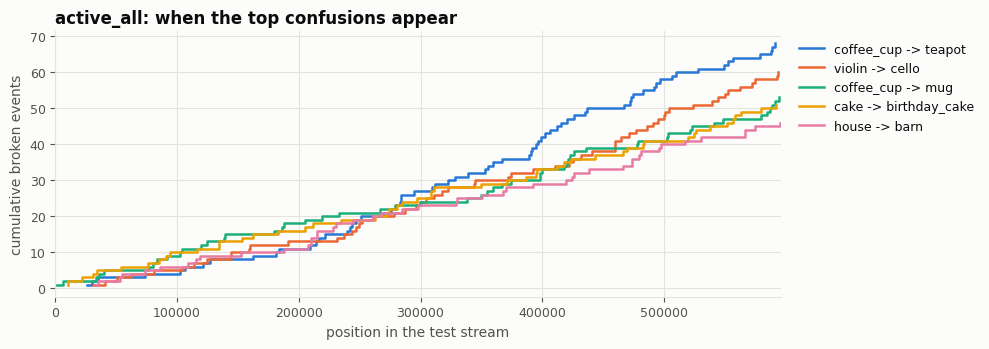

In [7]:
view.plot_onset();

The first two times Ramen makes its most frequent broken confusion. Top row: the query and the cache entries it retrieved with the largest weight (`w` = share of the update). Bottom rows: the most recent images in the queue of the class it predicted. Red = filed under a class that is not the image's true class.

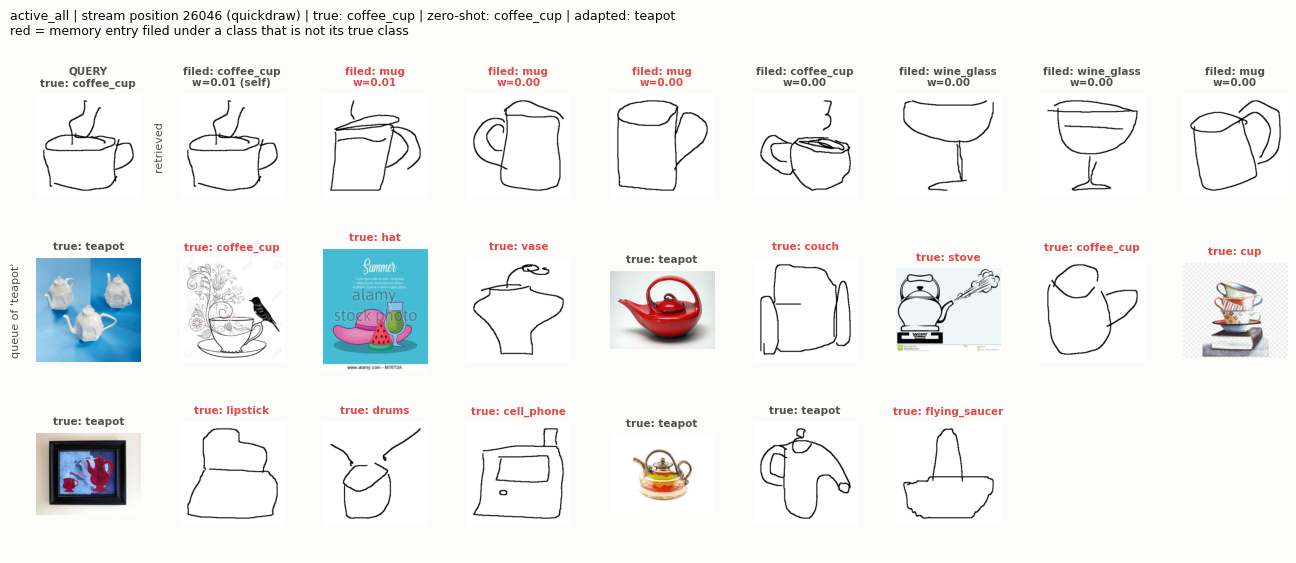

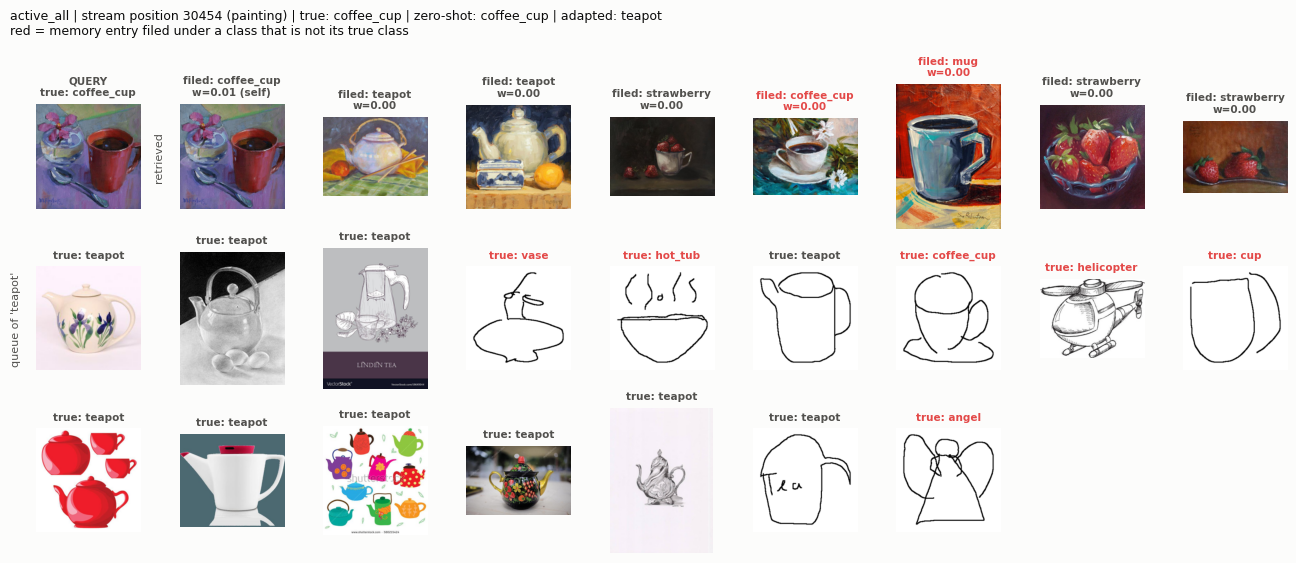

In [8]:
(true_name, pred_name) = view.pairs(top=1).index[0].split(' -> ')
view.show_pair(true_name, pred_name, n=2);

### The best zero-shot-weighted variant
The same view for the most accurate non-`all` variant, then how often it still makes Ramen's top confusions.

In [9]:
best = summary(VARIANTS).drop('active_all').accuracy.idxmax()
print('best variant:', best)
best_view = CacheViewer(exp, best)
best_view.pairs()

best variant: active_prob_T3


,count,first position,median position,queue: query class %,queue: correctly filed %
clock -> alarm_clock,85,7907,348235.0,19.9,52.7
bird -> parrot,81,1295,324571.0,14.1,72.4
foot -> toe,78,8461,256518.0,6.2,10.1
coffee_cup -> mug,67,6250,374654.0,18.6,52.3
pants -> shorts,62,382,265046.5,2.8,59.3
cake -> birthday_cake,59,10221,284964.0,26.4,58.2
leg -> knee,54,8696,293763.0,21.2,42.8
trumpet -> trombone,54,943,308499.0,15.2,65.5
nail -> lipstick,48,31396,323235.5,16.4,45.8
shoe -> flip_flops,45,62635,306079.0,6.0,69.4


In [10]:
ramen_pairs = view.pairs(top=10)
best_counts = best_view.pairs(top=10**6)['count']
pd.DataFrame({'Ramen': ramen_pairs['count'], best: best_counts.reindex(ramen_pairs.index).fillna(0).astype(int)})

,Ramen,active_prob_T3
coffee_cup -> teapot,68,32
violin -> cello,60,26
coffee_cup -> mug,53,67
cake -> birthday_cake,51,59
house -> barn,46,34
pants -> shorts,36,62
finger -> hand,35,41
pear -> teapot,34,12
truck -> tractor,34,14
trumpet -> trombone,33,54


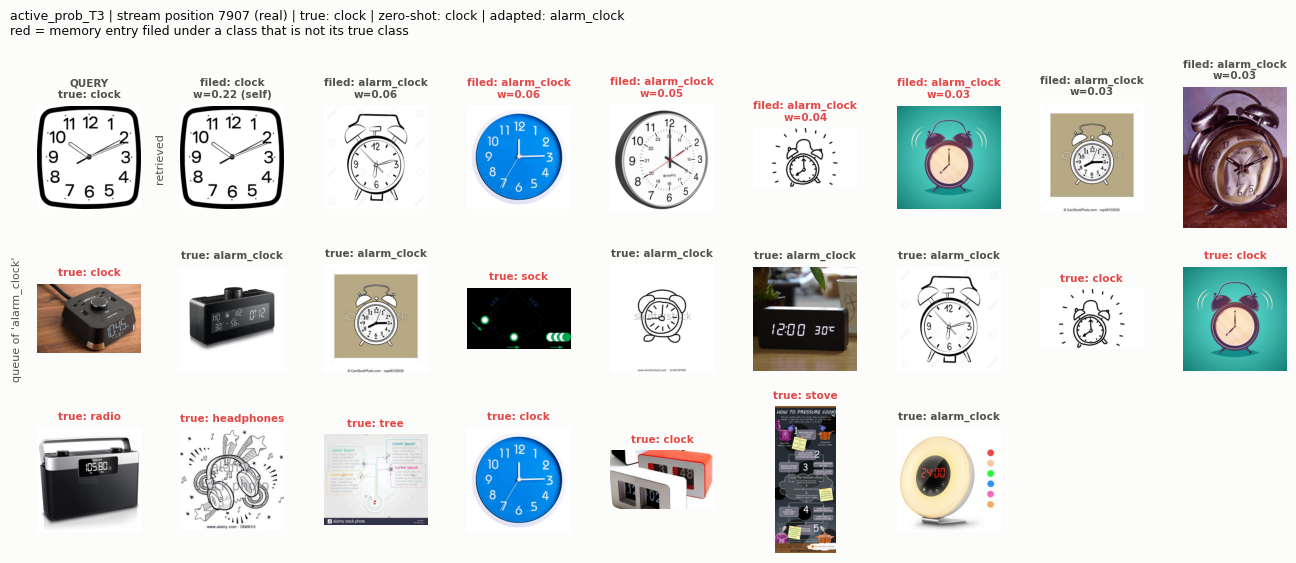

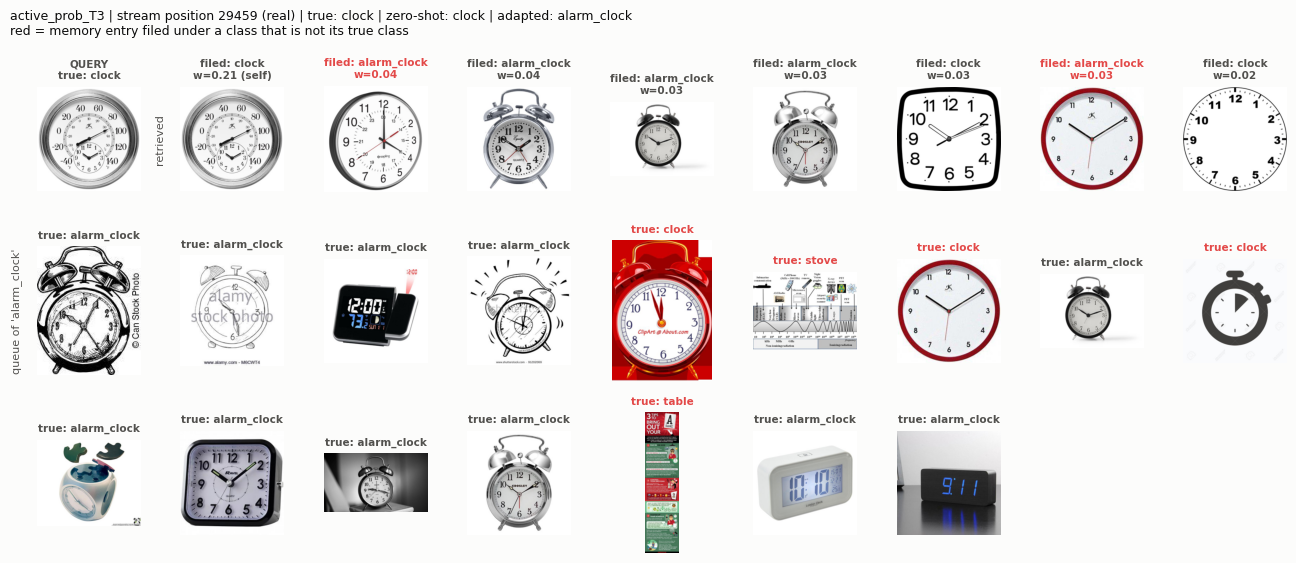

In [11]:
(true_name, pred_name) = best_view.pairs(top=1).index[0].split(' -> ')
best_view.show_pair(true_name, pred_name, n=2);

## Notes
- Seed 0 only. Before claiming a gain, run the winning variant at seeds 0-4 (`seed=` in `make_experiment`) and compare seed by seed with Ramen.
- Earlier results to keep in mind: restricting the support to cleaner entries (RamenClean, `agree` write rule) raised purity but lost accuracy because the effective support shrank, and per-sample adaptation alone was below Ramen on DomainNet. Small `top_m` shrinks the support the same way; check `self weight` alongside accuracy.
- `CacheViewer.show(position)` shows any single sample; `view.events()` gives the full per-event table to pick positions from (for example events late in the stream, when queues are full).